# Bike Sharing Project – Steps 7 and 8

> [!NOTE]
> **Setup for this notebook only.** This notebook continues [02_bike_sharing_project_ai_solution.ipynb](02_bike_sharing_project_ai_solution.ipynb) after step 6. The next two cells repeat the imports and the data preparation of steps 2–5 (load, split, `prepare()`, `X_train` / `y_train` and the five folds), so the notebook runs on its own. When step 7 is merged into notebook 02, these two cells are not needed.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# only warnings, not one log line per try
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
df = pd.read_csv("data/bike_sharing.csv")
df["datetime"] = pd.to_datetime(df["datetime"])

df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)


def prepare(data):
    """All manual changes to the data, collected in one place."""
    data = data.copy()
    dt = data["datetime"]

    # 1. the hour 02:00 on the second Sunday of March does not exist (clocks go forward)
    nonexistent = (dt.dt.month == 3) & (dt.dt.dayofweek == 6) & dt.dt.day.between(8, 14) & (dt.dt.hour == 2)
    data = data[~nonexistent]
    dt = data["datetime"]

    # 2. calendar features
    data["hour"] = dt.dt.hour
    data["weekday"] = dt.dt.dayofweek
    data["month"] = dt.dt.month
    data["year"] = dt.dt.year

    # 3. + 4. flags for holidays and working days
    data["is_holiday"] = data["holiday"].notna().astype(int)
    data["is_working_day"] = ((data["weekday"] < 5) & (data["is_holiday"] == 0)).astype(int)

    # 5. drop replaced, redundant and leaking columns
    return data.drop(columns=["holiday", "feels_like", "weather_code", "casual", "member"])


df_train_prep = prepare(df_train)
X_train = df_train_prep.drop(columns=["rentals", "datetime"])
y_train = df_train_prep["rentals"]

# the same five folds for every model, so the comparison is fair
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (14014, 12)
y_train: (14014,)


## Step 7 – Ensembles

Step 6 tuned Ridge with `RandomizedSearchCV` and the decision tree with `GridSearchCV`. The ensembles have more hyperparameters (XGBoost has six), and every try is expensive: one try trains the model five times, once per fold. So from here on the tuning is done with **Optuna**, which spends its tries where good settings are likely.

### How Optuna works

`RandomizedSearchCV` draws every try at random, no matter how the earlier tries went. Optuna's default sampler, **TPE** (Tree-structured Parzen Estimator), learns from them: after a few random start-up tries, it splits the tries so far into "good" and "bad" ones and draws the next settings from the region where good tries are more likely than bad ones. So the search narrows down on good settings instead of drawing blindly.

How it works in code:
- An **objective** function takes a `trial`, asks it for hyperparameters (`trial.suggest_int`, `suggest_float`, `suggest_categorical`), trains the model and returns the score to minimise, here the CV RMSE.
- A **study** calls the objective `n_trials` times and keeps the best settings.
- `suggest_float(..., log=True)` searches on a log scale, by factors of 10, like `loguniform` in step 6. That suits `learning_rate` and penalties, where 0.02 vs. 0.2 matters more than 0.18 vs. 0.2.
- The budgets here are small (8, 10 and 5 tries) to keep the run time at a few minutes. More tries would search more thoroughly; the code stays the same, only `n_trials` changes.

Two small helpers:
- `cv_rmse()` scores a model with the five folds and returns the mean CV RMSE.
- `run_study()` runs an Optuna study and prints the best score and settings. `TPESampler(seed=42, n_startup_trials=3)`: the first 3 tries are random, from the 4th on TPE learns from the earlier ones (the default is 10 random tries, which would use up most of the small budgets here). `seed=42` makes the tries the same on every run. All studies are kept in `studies` for the plot further down.

In [3]:
studies = {}


def cv_rmse(model):
    """Mean CV RMSE over the five folds."""
    return -cross_val_score(model, X_train, y_train, cv=kfold,
                            scoring="neg_root_mean_squared_error").mean()


def run_study(name, objective, n_trials):
    start = time.time()
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=3))
    study.optimize(objective, n_trials=n_trials)
    studies[name] = study
    print(f"{name}: best CV RMSE {study.best_value:.1f} after {n_trials} tries "
          f"({(time.time() - start) / 60:.1f} min)")
    print("best parameters:", {k: round(v, 3) if isinstance(v, float) else v
                               for k, v in study.best_params.items()})
    return study

### Random forest

Many deep trees, each trained on a bootstrap sample of the rows and with a random subset of the features at every split; their predictions are averaged. Tuned:
- `max_features`: the share of the features each split may look at (0.3 to 1.0). Fewer features make the trees more different from each other.
- `min_samples_leaf`: the fewest training hours per leaf (1 to 9).
- `max_depth`: no limit, 15 or 25.

`n_estimators=200` is fixed: more trees never hurt the accuracy, they only cost time.

In [4]:
def rf_objective(trial):
    model = RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1,
        max_features=trial.suggest_float("max_features", 0.3, 1.0),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 9),
        max_depth=trial.suggest_categorical("max_depth", [None, 15, 25]),
    )
    return cv_rmse(model)


rf_study = run_study("Random forest", rf_objective, n_trials=8)

Random forest: best CV RMSE 164.5 after 8 tries (0.6 min)
best parameters: {'max_features': 0.894, 'min_samples_leaf': 3, 'max_depth': 15}


### XGBoost

Boosting builds the trees **one after another**: each new tree is fitted to the errors the trees before it still make. Tuned:
- `n_estimators` (300 to 999) and `learning_rate` (0.02 to 0.2, log scale): how many trees, and how much of each tree's correction is added. A small rate with many trees learns slowly but generalises better.
- `max_depth` (4 to 8): kept small, boosting combines many weak trees.
- `subsample` and `colsample_bytree` (0.6 to 1.0): the share of rows and features each tree sees, randomness as in the forest.
- `min_child_weight` (1 to 9): roughly the fewest hours per leaf.

Six hyperparameters that work together, so XGBoost gets the most tries (10).

In [5]:
def xgb_objective(trial):
    model = XGBRegressor(
        random_state=42, n_jobs=-1,
        n_estimators=trial.suggest_int("n_estimators", 300, 999),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 4, 8),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 9),
    )
    return cv_rmse(model)


xgb_study = run_study("XGBoost", xgb_objective, n_trials=10)

XGBoost: best CV RMSE 137.1 after 10 tries (2.2 min)
best parameters: {'n_estimators': 705, 'learning_rate': 0.054, 'max_depth': 8, 'subsample': 0.717, 'colsample_bytree': 0.923, 'min_child_weight': 8}


### CatBoost

CatBoost is another boosting library. It builds **symmetric** trees (the same split on every level), which makes it robust with few settings. `hour`, `weekday` and `month` stay numbers: as numbers, a tree can group neighbouring hours in one split. Tuned:
- `depth` (4 to 10): the depth of each tree.
- `learning_rate` (0.02 to 0.3, log scale).
- `l2_leaf_reg` (1 to 10, log scale): a penalty on large leaf values, like `alpha` in Ridge.

`iterations=1000` is fixed. Each try takes about a minute (five trainings of 1,000 trees), so only 5 tries.

In [6]:
def cat_objective(trial):
    model = CatBoostRegressor(
        iterations=1000, random_seed=42, verbose=0,
        depth=trial.suggest_int("depth", 4, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 10, log=True),
    )
    return cv_rmse(model)


cat_study = run_study("CatBoost", cat_objective, n_trials=5)

CatBoost: best CV RMSE 128.4 after 5 tries (4.4 min)
best parameters: {'depth': 10, 'learning_rate': 0.089, 'l2_leaf_reg': 3.423}


### How the searches went

Each dot is one try; the line is the best CV RMSE found so far. The first 3 tries are random; after that, TPE draws from the region where the good tries lie.

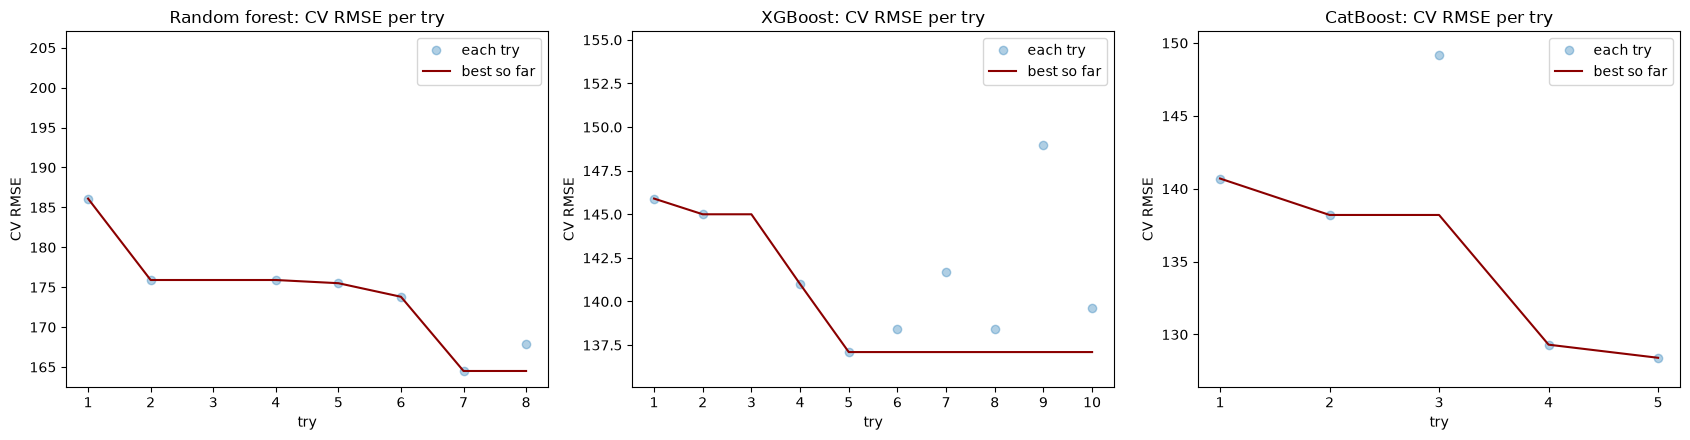

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, study) in zip(axes, studies.items()):
    values = np.array([t.value for t in study.trials])
    tries = np.arange(1, len(values) + 1)
    ax.plot(tries, values, "o", alpha=0.35, label="each try")
    ax.plot(tries, np.minimum.accumulate(values), color="darkred", label="best so far")
    # zoom in on the good region; a few bad early tries may lie above it
    ax.set_ylim(values.min() - 2, np.percentile(values, 90) + 5)
    ax.set_title(f"{name}: CV RMSE per try")
    ax.set_xlabel("try")
    ax.set_xticks(tries)
    ax.set_ylabel("CV RMSE")
    ax.legend()
plt.tight_layout()
plt.show()

**Finding:**
- **Random forest:** the big step comes at try 7, the first with `max_depth=15` (164.5), and try 8 with the same limit is second best (167.9). Limiting the depth helps the forest here more than the share of features. Try 3 lies above the chart (239): with `max_features=0.31`, most splits cannot see the important features.
- **XGBoost:** after the 3 random start-up tries, TPE finds the best setting in try 5 (137.1: 705 trees, `learning_rate=0.054`, `max_depth=8`). Four of the five later tries stay within 5 points of it (138–142); the outlier, try 9 (149), uses shallow trees (`max_depth=5`) with a high learning rate.
- **CatBoost:** the two tries with the deepest trees (`depth=10`) are clearly the best (129.3 and 128.4), and the shallowest (`depth=4`) is the worst (149.2). Deeper trees work better here, and 10 is the edge of the search range (see the conclusion).

### Combining models: voting and stacking

The three tuned models are trained on the whole training set and combined:
- **Voting** averages their predictions with equal weights (a fixed rule).
- **Stacking** learns the combination: a `Ridge` is trained on the **out-of-fold** predictions of the three models, so it learns how much to trust each one from predictions on rows the models did not see.

In [8]:
best_rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1, **rf_study.best_params)
best_xgb = XGBRegressor(random_state=42, n_jobs=-1, **xgb_study.best_params)
best_cat = CatBoostRegressor(iterations=1000, random_seed=42, verbose=0, **cat_study.best_params)
for model in (best_rf, best_xgb, best_cat):
    model.fit(X_train, y_train)

base_models = [("rf", best_rf), ("xgb", best_xgb), ("cat", best_cat)]
voting = VotingRegressor(base_models)
stacking = StackingRegressor(base_models, final_estimator=Ridge(), cv=kfold)

cv_voting = cv_rmse(voting)
cv_stacking = cv_rmse(stacking)
print(f"Voting   CV RMSE: {cv_voting:.1f}")
print(f"Stacking CV RMSE: {cv_stacking:.1f}")

# fit both on the whole training set for step 8
voting.fit(X_train, y_train)
stacking.fit(X_train, y_train)

# how much does the stacking Ridge trust each base model?
print("stacking weights:", dict(zip(["rf", "xgb", "cat"], stacking.final_estimator_.coef_.round(2))))

Voting   CV RMSE: 135.3
Stacking CV RMSE: 127.9


stacking weights: {'rf': np.float64(-0.05), 'xgb': np.float64(0.2), 'cat': np.float64(0.86)}


### Model selection by cross-validated RMSE

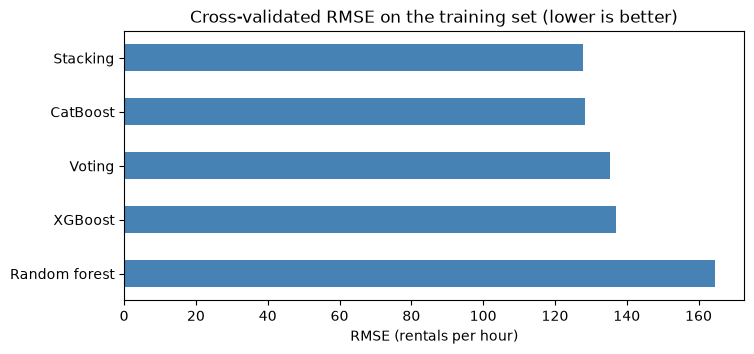

,CV RMSE
Stacking,127.9
CatBoost,128.4
Voting,135.3
XGBoost,137.1
Random forest,164.5


In [9]:
cv_results = pd.Series({
    "Random forest": rf_study.best_value,
    "XGBoost": xgb_study.best_value,
    "CatBoost": cat_study.best_value,
    "Voting": cv_voting,
    "Stacking": cv_stacking,
}, name="CV RMSE").sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
cv_results.sort_values(ascending=False).plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Cross-validated RMSE on the training set (lower is better)")
ax.set_xlabel("RMSE (rentals per hour)")
plt.show()

cv_results.round(1).to_frame()

**Model selection:** the **stacking ensemble has the lowest CV RMSE (127.9)** and is chosen as the final model.
- **CatBoost is the strongest single model** (128.4), ahead of XGBoost (137.1) and far ahead of the random forest (164.5). Boosting corrects the errors of the trees before it, while a forest only averages trees that all make similar errors.
- **Stacking gains only 0.5 over CatBoost alone**, well within the variation between folds. The Ridge on top trusts CatBoost most (weight 0.86), XGBoost a little (0.20), and gives the forest a small negative weight (−0.05): the forest adds nothing the other two do not already know. If simplicity or speed mattered more, CatBoost alone would be just as good.
- **Voting (135.3) is worse than CatBoost alone:** with equal weights, the much weaker forest gets a third of the say.

## Step 8 – Test set and final evaluation

The test set is unlocked now. It gets the same manual changes with the same `prepare()` function, and every model is scored on it once. RMSE is the main metric; MAE and R² are added for context.

In [10]:
df_test_prep = prepare(df_test)
X_test = df_test_prep.drop(columns=["rentals", "datetime"])
y_test = df_test_prep["rentals"]
print(f"rows dropped: {len(df_test) - len(df_test_prep)}")
print("X_test:", X_test.shape)

models = {"Random forest": best_rf, "XGBoost": best_xgb, "CatBoost": best_cat,
          "Voting": voting, "Stacking": stacking}

rows = []
for name, model in models.items():
    pred_test = model.predict(X_test)
    rows.append({
        "Model": name,
        "Train RMSE": root_mean_squared_error(y_train, model.predict(X_train)),
        "CV RMSE": cv_results[name],
        "Test RMSE": root_mean_squared_error(y_test, pred_test),
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test R²": r2_score(y_test, pred_test),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE")
results.round({"Train RMSE": 1, "CV RMSE": 1, "Test RMSE": 1, "Test MAE": 1, "Test R²": 3})

rows dropped: 0
X_test: (3504, 12)


,Train RMSE,CV RMSE,Test RMSE,Test MAE,Test R²
Model,,,,,
Stacking,46.2,127.9,122.5,73.5,0.962
CatBoost,49.0,128.4,122.9,73.9,0.962
Voting,59.6,135.3,128.0,75.8,0.959
XGBoost,45.5,137.1,129.9,78.5,0.957
Random forest,102.7,164.5,154.3,94.7,0.940


**Finding:**
- The stacking ensemble has a test RMSE of **122.5** rentals per hour (MAE 73.5, R² 0.962). CatBoost alone is practically the same (122.9).
- **CV and test agree:** every model scores a little better on the test set than in cross-validation, and the ranking is the same. So the cross-validation predicted the test performance well.
- **Training vs. test:** the boosting models and stacking reach a training RMSE of 45–49, but 122–130 on the test set: they partly memorise the training hours. That is why the models are chosen by CV RMSE, not by training RMSE. The forest's gap is smaller (103 vs. 154), because `min_samples_leaf=3` and `max_depth=15` keep its trees from growing to single hours.

**Predictions below 0.** Negative rentals are impossible. The random forest cannot predict them: it only averages rentals from the training data. Boosting can, because it adds up many corrections, and so can the stacking Ridge, which combines the models with free weights. This happens in quiet night hours. Clipping the predictions at 0 fixes it:

In [11]:
best_model = models[cv_results.index[0]]  # the model with the lowest CV RMSE
pred_best = best_model.predict(X_test)
pred_clipped = np.clip(pred_best, 0, None)

print(f"final model: {cv_results.index[0]}")
print(f"predictions below 0: {(pred_best < 0).sum()} of {len(pred_best)} hours")
print(f"Test RMSE raw:     {root_mean_squared_error(y_test, pred_best):.1f}")
print(f"Test RMSE clipped: {root_mean_squared_error(y_test, pred_clipped):.1f}")

final model: Stacking
predictions below 0: 54 of 3504 hours
Test RMSE raw:     122.5
Test RMSE clipped: 122.4


## Conclusion

- **Final model:** a stacking ensemble of a random forest, XGBoost and CatBoost, each tuned with Optuna and combined by a Ridge. On the test hours it is off by **≈ 74 rentals per hour typically (MAE)**, with an RMSE of **≈ 122** and an R² of 0.962: it explains about 96 % of the variation in hourly rentals.
- **CatBoost carries the ensemble:** it gets 86 % of the stacking weight and scores almost the same on its own.
- **Predictions below 0:** 54 of the 3,504 test hours were predicted slightly below 0. Clipping at 0 fixes that and even lowers the RMSE a little (122.5 → 122.4), so the final predictions are clipped.
- **Next step for the tuning:** the searches are short (8, 10 and 5 tries), and two best settings lie at the **edge of their range**: CatBoost `depth=10` and XGBoost `max_depth=8` are the largest values allowed. Deeper trees may do even better, so the ranges should be widened and the searches given more tries. Only the ranges and `n_trials` change; the rest of the code stays the same.